<a href="https://colab.research.google.com/github/Berrybanana23/Data_Science_Simulation_Exercises/blob/main/Data_Science_Simulation_Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data Science Simulation Exercises
This is a collection of the data science exercises I've completed as part of my 'Data Science for Brain and Behaviour' module.<br>
I'm storing them here so I can look back on what I've done and keep a record of how far I've come!<br>
I will try to keep this updated as the course goes on.<br>
<br>

###CREDITS:
These exercises were adapted by lecturers at the University of Birmingham from the [Berkeley Data Science Course](https://github.com/data-8/data8assets/tree/gh-pages).<br>
All credit goes to them for creating the exercises! Thank you for the help!


---






---


## Three Boys Problem


---


This exercise asked 'in a family of 4 children, how likely is it that 3 would be boys?'.<br>
This exercise introduced me to creating simulations to understand what the data would look like in a 'fair world' where there was an equal chance of getting boys or girls. <br>

First, I created a simple version to fit the brief. Then, because I had experience of Python and knew how to create loops, I made a versatile version which you could plug any values into.<br>


---



**My to-do list:**<br>
Simulate [num1] boys in families of size [num2]<br>

**STEPS:**
- Create empty array for boys_in_fam
- Set counter to 0

- Create loop for length of boys_in_fam
- Simulate family of children
- Count boys (1s)
- Add to boys_in_fam array
- Increase counter by 1

- Logical search - which families have n_boys boys?
- Sum
- Divide total by sample size to find percentage/probability
- Make sure thing returns the right info

In [1]:
# IMPORT PACKAGES
import numpy as np
import matplotlib.pyplot as plt

In [7]:
# VARIABLES
n_boys = 3 #The amount of boys we're looking at the probabilty of having
n_child = 4 #The amount of children in the family
sample_size = 10000 #The number of simulations to run

246/1000 families with 4 children in the sample have 3 boys.
The probabilty of having 3 boys in a family of 4 children is 0.246 or 24.6%.


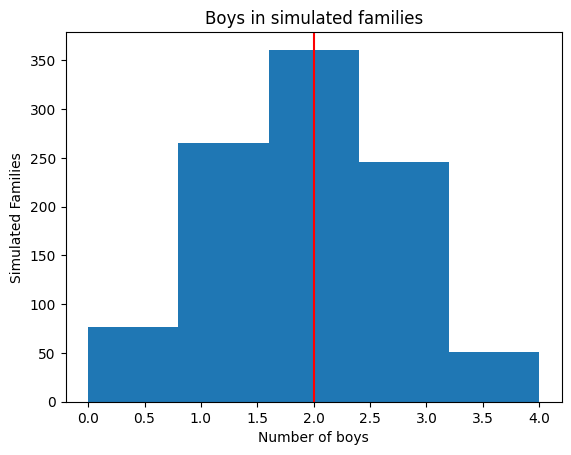

In [14]:
# CREATING A FUNCTION TO MAKE THE SIMULATION VERSATILE

def simulate_family(n_boys, n_child, sample_size):
    n_boys_each_family = np.full(shape=sample_size, fill_value=np.nan)
    #print(n_boys_each_family) #Checking empty array was correct

    for i in range(len(n_boys_each_family)):
        family=np.random.randint(low=0, high=2, size=n_child)
        #print(f"Family {a+1} has {np.sum(family)} boys.") #Show simulated family
        n_boys_each_family[i]= np.sum(family)
        #print(n_boys_each_family) #Checks that overall array is updating.

    fam_w_n_boys=np.sum(n_boys_each_family==n_boys)
    print(f"{fam_w_n_boys}/{sample_size} families with {n_child} children in the sample have {n_boys} boys.")

    prob_n_boys = fam_w_n_boys / sample_size
    plt.hist(n_boys_each_family, bins=5)
    plt.title("Boys in simulated families")
    plt.xlabel("Number of boys")
    plt.ylabel("Simulated Families")
    plt.axvline(2, color="red")

    return(prob_n_boys)


prob_n_boys = simulate_family(n_boys, n_child, sample_size)
print(f"The probabilty of having {n_boys} boys in a family of {n_child} children is {prob_n_boys} or {prob_n_boys*100}%.")



---


---




# Henry VII Version


---

TASK:
Henry VIII had at least 15 children -
- four survived
- 11 were stillborn or died in infancy
- 2 surviving children were boys

How likely is it that 2 of 15 were boys?<br>


**STEPS (need to):**
- Create empty array length of sample size (1000)

- Create loop for length of array/1000 samples
- Simulate each child (0/1 for girl/boy) in 1 version of the family
- Count boys (True-s)
- Add to array
- Increase counter by 1

- Count versions with 2 boys
- Sum

The probability of Henry having 2 boys is 0.00345%.


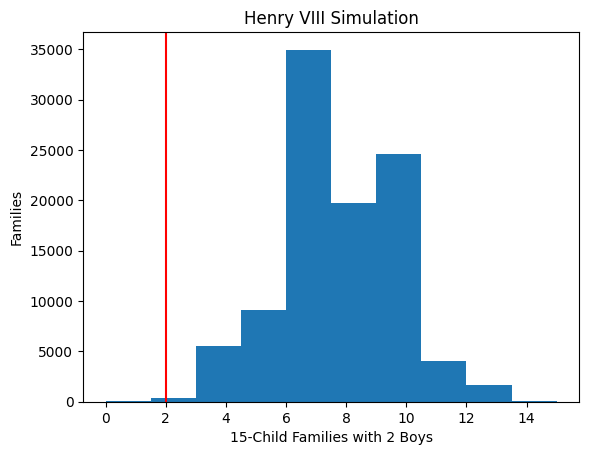

In [15]:
henry_fam = 15 #Henry's 15 kids
boys = 2 #no of boys we're looking for
sample_size = 100000

def henry_simulation(henry_fam, boys, sample_size):
    sample = np.full(shape=sample_size, fill_value=np.nan)

    for i in range(len(sample)):
        family=np.random.randint(0,2,henry_fam)
        sample[i]=np.sum(family)
        #print(i)
        #print(sample)

    plt.hist(sample)
    plt.title('Henry VIII Simulation')
    plt.xlabel('15-Child Families with 2 Boys')
    plt.ylabel('Families')
    plt.axvline(2, color="red") #Plotted at real-world outcome: likelihood of 2 boys occurring by chance in real-world outcome.

    fam_w_boys = np.sum(sample == boys)
    #print(fam_w_boys)
    prob_2_boys = fam_w_boys / sample_size
    #print(prob_2_boys)
    return prob_2_boys

prob_2_boys = henry_simulation(henry_fam, boys, sample_size)
print(f"The probability of Henry having 2 boys is {prob_2_boys}%.")




---


---


## The Swain Jury Exercise


---

In 1965, a Black man called Swain was convicted of sexual assault in Alabama and sentenced to death by an all-white jury. The case was appealed due to the fact that the jury were all white (despite the fact that 26% of eligible jurors in the county were Black). <br>
Our task was to determine if it was statistically fair for 0 of the 12 jurors to be Black, or if discrimination was likely to be at play.

TASK:<br>
Creating a fair jury because we know what that would look like!<br>
26% of population are Black, 74% white. A fair jury will reflect these numbers.<br>

0.26 = p of picking Black jury member<br>
0.74 = p of picking white jury member

2 questions:
- Is it fair that 8/100 empaneled jurors were Black?
- Is if fair that none of those jurors made it to the jury?

STEPS:
- Create empty array length of sample size (1000+)<br>
- Create loop for length of array
- Simulate each jury
- Count Black members of jury
- Add to array<br>
- Count number of Black jurors in sample of juries.
- Sum

There were 3214 Black jurors in a sample of 1000 juries of 12 people.
26.78% of the jurors selected in total were Black.
29/1000 juries had 0 Black jurors in the sample, or 2.9% of the sample.
This makes getting 0 Black jurors a fairly uncommon occurrence (p = 0.03).


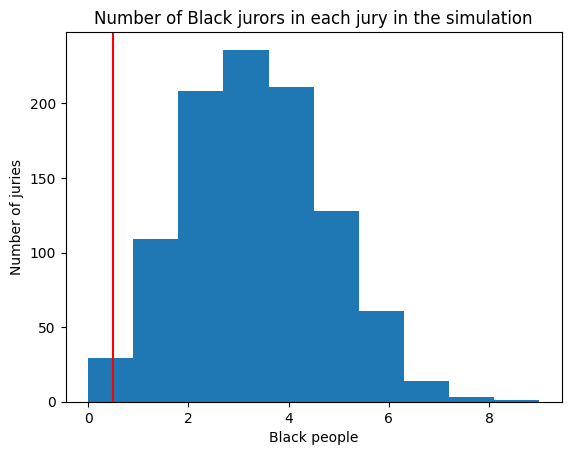

In [10]:
import numpy as np
import matplotlib.pyplot as plt

sample_size = 1000
jury_size = 12
target = 0

def simulate_jury(sample_size, jury_size, target):
    sample = np.full(shape=sample_size, fill_value=np.nan)
    # print(sample)
    # print(range(len(sample)))

    for i in range(len(sample)):
        jury1=np.random.randint(low=0, high=100, size=jury_size)
        black_members = np.sum(jury1 <= 26)
        sample[i] = int(black_members)
        #print('jury1', jury1)
        #print('BM:', black_members)
        #print('i:', i)

    #print('Black jurors in each jury:', sample)
    black_jurors = np.sum(sample)
    no_black_jurors = np.sum(sample == target)

    #PLOTTING DIAGRAM
    plt.hist(sample)
    plt.title('Number of Black jurors in each jury in the simulation')
    plt.xlabel('Black people')
    plt.ylabel('Number of juries')
    plt.axvline(0.5, color="red")

    #DESCRIBING PROBABILITY
    print(f"There were {int(black_jurors)} Black jurors in a sample of {sample_size} juries of {jury_size} people.")
    print(f"{round(black_jurors/(sample_size*jury_size)*100, 2)}% of the jurors selected in total were Black.")
    print(f"{no_black_jurors}/{sample_size} juries had 0 Black jurors in the sample, or {round(no_black_jurors/sample_size*100, 2)}% of the sample.")
    print(f"This makes getting 0 Black jurors a fairly uncommon occurrence (p = {round(no_black_jurors/sample_size, 2)}).")

    return sample

simulation = simulate_jury(sample_size, jury_size, target)



---



---

## The Crooked Euro


---


Is the Euro coin really perfectly balanced and symmetric?
Some researchers [found](https://www.theguardian.com/world/2002/jan/04/euro.eu2) that when the Euro was tossed 250 times, the coin came up heads 139 times and tails 111.
For a fair and balanced coin, the chance of each side should be 0.5 (50%). We expect 50% of the tosses to be heads, or around 125.<br>
Is 139 too high for the coin to be fair?

This task involved simulating coin tosses in a 'fair world' where it really IS a 50% chance of getting either side. If getting 139 heads in this world is unrealistic, we have to question if the coin really IS fair.



In [16]:
# One trial of the coin-tossing problem.
# Toss 150 coins, each with a 50% chance of giving heads (1).
tosses = np.random.randint(0, 2, size=250)
# Count the number of heads.
n_heads = np.sum(tosses)

#print(n_heads)

In [27]:
# Array to store the number of heads on each trial.
counts = np.full(shape=10000, fill_value=np.nan)
for i in range(len(counts)):
    # Each indented statement gets run on every trial
    tosses = np.random.randint(0, 2, size=250)
    n_heads = np.sum(tosses)
    counts[i] = n_heads
p_crooked = np.count_nonzero(counts >= 139) / 10000
print(f"The probability of getting 139 or more heads in 250 coin tosses, if the coin is fair: {p_crooked} or {p_crooked*100}%")

The probability of getting 139 or more heads in 250 coin tosses, if the coin is fair: 0.0454 or 4.54%


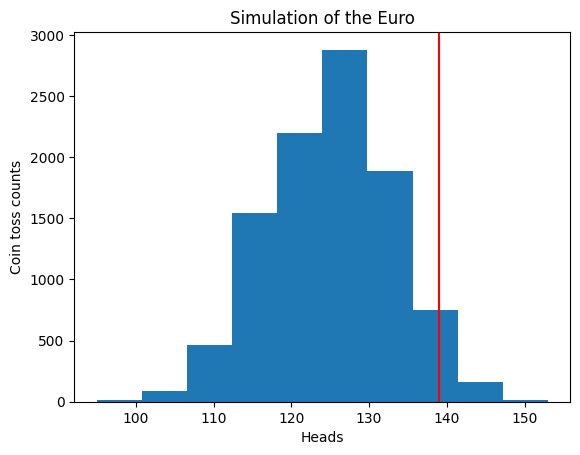

In [28]:
# Plotting the data

plt.hist(counts)
plt.title("Simulation of the Euro")
plt.xlabel("Heads")
plt.ylabel("Coin toss counts")
plt.axvline(139, color="red")




---


---

#Penalty Shoot-Out Simulation


---

"Jen is the penalty taker for her football team.
She's been doing this for a long time.  She thinks she normally has a 80%
chance of scoring.

In the last 15 penalties she has taken, she has been trying a new technique.
She scored on all 15 penalties.
How certain can she be that this would not have happened, using the old
technique?

As usual, we first consider the logic for a single trial.  A single trial is
15 of Jen's penalty shots.  The result of the trial is the number of penalty
shots that went in.  For each shot, there is a 80% chance of it going in.
Careful, this is different from the case of the coin toss, where each coin
toss had a 50% chance of being heads."

In [30]:
# ONE TRIAL VERSION

#- One trial is 15 penalty shots, each with 80% chance of scoring.
shots = np.random.randint(low=0, high=100, size=15) #Will get value from 0-100, scores of 0-80 are a goal, scores of >80 are a miss.
scores = np.count_nonzero(shots<=80) # Scores should be some number between 0 and 15, with higher values being much more likely than lower values (because of the 80% chance of scoring).

print(shots)
print(scores)

[38 48 23  8 94 24 62 11 19 21 11 10 93 11 62]
13


In [31]:
#- Calculate the probability of Jen scoring 15 out of 15 penalties.
counts = np.zeros(10000)
for i in np.arange(10000):
    # Each indented statement gets run on every trial
    shots = np.random.randint(low=0, high=101, size=15)
    scores = np.count_nonzero(shots<=80)
    counts[i] = scores
p_15_of_15 = np.count_nonzero(counts == 15) / 10000

print(f"The probability of Jen scoring 15/15 penalties: {p_15_of_15} or {p_15_of_15*100}%")

The probability of Jen scoring 15/15 penalties: 0.034 or 3.4000000000000004%


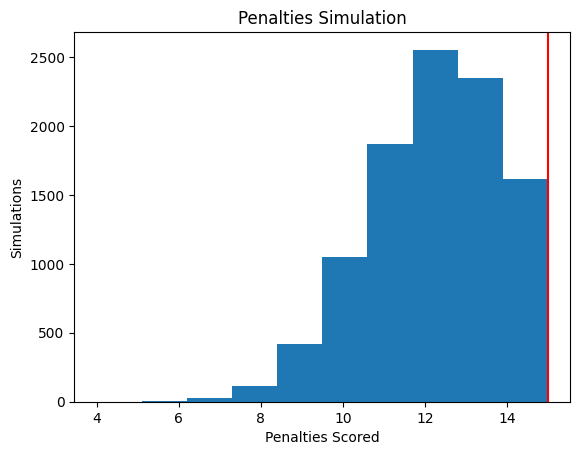

In [33]:
# Plotting the data

plt.hist(counts)
plt.title("Penalties Simulation")
plt.xlabel("Penalties Scored")
plt.ylabel("Simulations")
plt.axvline(15, color="red")



---



---
#Dice Roll


---

"John is playing Monopoly.  His piece, the top hat, is sitting in a really bad
spot, just in front of some expensive hotels.  He is about to roll the two
6-sided die.  He needs a score of 10 or more to skip over the hotels.  What
are John's chances?

Solve by simulation."


In [35]:
# ONE TRIAL
dice = np.random.randint(1, 7, size=2)
score = np.sum(dice)
# The addition of the two dice. This should result in numbers like 7 or 6
# more often than numbers like 2 or 12.
print(dice)
print(score)

[5 3]
8


In [40]:
# FOR-LOOP VERSION

#- Calculate the probability of getting 10 or more with two dice.
counts = np.zeros(10000)
for i in np.arange(10000):
    dice = np.random.randint(1, 7, size=2) #rolling two 6-sided dice
    score = np.sum(dice) #add the scores
    counts[i] = score #store total score in array 'counts'
p_10_or_more = np.count_nonzero(counts>=10) / 10000 #amount of times scores in 'count' are more than 10 / size of sample (10000)

print(counts)
print(f"The probability of John rolling 10 or more: {p_10_or_more} or {p_10_or_more*100}%")

[ 7. 11.  7. ...  6.  8. 11.]
The probability of John rolling 10 or more: 0.1645 or 16.45%


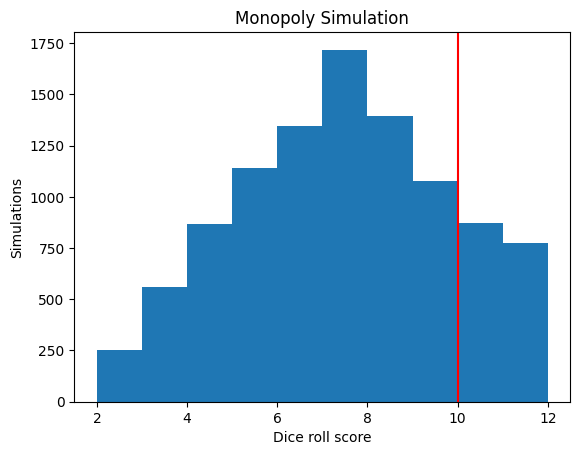

In [41]:
plt.hist(counts)
plt.title("Monopoly Simulation")
plt.xlabel("Dice roll score")
plt.ylabel("Simulations")
plt.axvline(10, color="red")

# Blackjack Simulation
Given any three random playing cards, what is the chance that the ranks of the
three cards add up to 21?

10, jack, queen and king all count as 10.  For example, one way of getting 21
is a seven, a four and a king.

## Simple Version
Assume the ace counts as 1.<br>
Assume the three cards are each dealt from the top of a full shuffled deck.<br>
Therefore, the procedure is:

* you shuffle, look at the top card, record the rank, you put it back.
* repeat twice more.

In [42]:
#-------------Sorting out a deck of cards----------

# SIMULATE RANKS OF CARDS IN A SUIT
# Ace is 1; Jack, Queen, King are all 10.
ranks = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 10, 10, 10])

#CREATE DECK OF CARDS
# Next - make a deck of cards by replicating ranks four times.
# The line below repeats each element four times.
card_deck = np.repeat(ranks, 4)
card_deck

array([ 1,  1,  1,  1,  2,  2,  2,  2,  3,  3,  3,  3,  4,  4,  4,  4,  5,
        5,  5,  5,  6,  6,  6,  6,  7,  7,  7,  7,  8,  8,  8,  8,  9,  9,
        9,  9, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10,
       10])

In [43]:
#-------------Single trial----------
#- "cards" should be an array with 3 elements, each of which comes from the "card_deck" array.
cards = np.random.choice(card_deck, size=3, replace=True)

#- "rank_total" should be the result of adding up the ranks in the cards.
rank_total = np.sum(cards)

# The result should be some number between 3 and 30 ... (why?) #minimum is 3 (3 aces), maximum is 30 (three 10s)
rank_total

np.int64(12)

The probability of pulling 3 cards and their rank value adding to 21: 0.077 or 7.7%


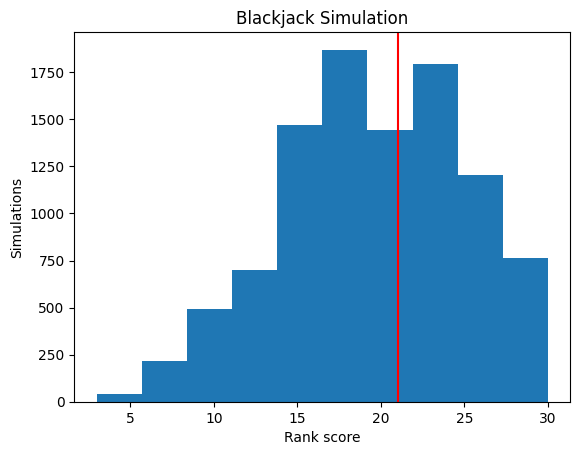

In [45]:
# -------------Function version with for-loop------------

# Ranks of all the cards in one suit.
ranks = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 10, 10, 10])
card_deck = np.repeat(ranks, 4)
sample_size = 10000
value_wanted = 21
cards_pulled = 3

def simulate_card_pull(sample_size, value_wanted, cards_pulled):
    counts= np.full(shape=sample_size, fill_value=np.nan)
    # print(counts)

    for i in range(len(counts)):
        cards = np.random.choice(card_deck, size=cards_pulled, replace=True)
        rank_total=np.sum(cards)
        counts[i] = rank_total

        # print(cards)
        # print(rank_total)
        # print(counts)

    plt.hist(counts)
    plt.title("Blackjack Simulation")
    plt.xlabel("Rank score")
    plt.ylabel("Simulations")
    plt.axvline(21, color="red")

    #print(counts)
    # print(value_wanted)
    # print(sample_size)
    p_total_21 = np.count_nonzero(counts==value_wanted)/sample_size
    return p_total_21

p_total_21 = simulate_card_pull(sample_size, value_wanted, cards_pulled)
print(f"The probability of pulling 3 cards and their rank value adding to 21: {p_total_21} or {p_total_21*100}%")

## Less Simple Version
Assume the cards are drawn as they were for the problem above.

Now the ace can count as 1 or as 11, whichever gives a total of 21.  To make things a bit simpler, the two options are:

* all aces in a hand count as 1, OR
* all aces in a hand count as 11.

Your job is to choose the option from the list above, that gives you 21, if that is possible.
In this situation, what are the chances of a total rank of 21?

In [46]:
# ----------VARIABLES------------

ranks = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 10, 10, 10])
card_deck = np.repeat(ranks, 4)
sample_size = 10000
value_wanted = 21
cards_pulled = 3

The probability of pulling 3 cards and their rank value adding to 21: 0.0841 or 8.41%


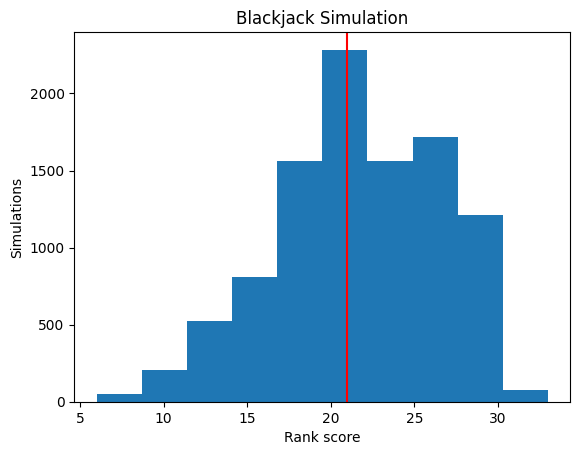

In [49]:
#-----------FUNCTION-------------

def simulate_card_pull(sample_size, value_wanted, cards_pulled):
    rank_totals_1 = np.full(shape=sample_size, fill_value=np.nan) #count if aces = 1
    rank_totals_11 = np.full(shape=sample_size, fill_value=np.nan) #count if aces = 11
    final_array = np.full(shape=sample_size, fill_value=np.nan)

    for i in range(sample_size):
        cards = np.random.choice(card_deck, size=cards_pulled, replace=True)
        #Store values if aces = 1
        aces = cards == 1
        rank_totals_1[i] = np.sum(cards)

        #Store values if aces = 11
        cards[aces] = 11
        rank_totals_11[i]=np.sum(cards)

        # print(cards)
        # print(rank_total)
        # print(counts)
    for i in range(sample_size):
        if rank_totals_1[i] == 21:
            final_array[i] = rank_totals_1[i]
        else:
            final_array[i] = rank_totals_11[i]

    plt.hist(final_array)
    plt.title("Blackjack Simulation")
    plt.xlabel("Rank score")
    plt.ylabel("Simulations")
    plt.axvline(21, color="red")

    # print(rank_totals_1)
    # print(rank_totals_11)
    # # print(value_wanted)
    # print(sample_size)
    p_flex_total_21 = np.count_nonzero(final_array==value_wanted)/(sample_size)

    return p_flex_total_21

p_flex_total_21 = simulate_card_pull(sample_size, value_wanted, cards_pulled)
print(f"The probability of pulling 3 cards and their rank value adding to 21: {p_flex_total_21} or {p_flex_total_21*100}%")